# Experiment 6 - Fuzzy Logic and Constraint Satisfaction

## Aim
To implement a simple fuzzy logic system and solve a constraint satisfaction problem using given rules and constraints.

## Exercises
1. Create a fuzzy logic system to determine **student performance** based on attendance and marks.
2. Create a simple **timetable problem** using variables, possible time slots, and constraints.
3. Change some fuzzy rules or constraints and observe how the final output or solution changes.


## 1. Fuzzy Logic - Student Performance

The system uses attendance and marks as inputs and produces a student-performance score. Attendance and marks are represented by Low, Medium, and High fuzzy sets. The output categories are Poor, Average, Good, and Excellent.

The implementation uses membership functions, fuzzy IF-THEN rules, minimum rule firing strength, maximum aggregation, and centroid defuzzification.


In [ ]:
import itertools
import matplotlib.pyplot as plt

def triangular(x,a,b,c):
    if x <= a or x >= c: return 0.0
    if x == b: return 1.0
    return (x-a)/(b-a) if x < b else (c-x)/(c-b)

def trapezoidal(x,a,b,c,d):
    if x < a or x > d: return 0.0
    if b <= x <= c: return 1.0
    if x < b: return (x-a)/(b-a)
    return (d-x)/(d-c)

def attendance_memberships(x):
    return {'Low':trapezoidal(x,0,0,35,55),'Medium':triangular(x,35,60,80),'High':trapezoidal(x,65,80,100,100)}

def marks_memberships(x):
    return {'Low':trapezoidal(x,0,0,35,50),'Medium':triangular(x,35,55,75),'High':trapezoidal(x,60,75,100,100)}

RULES=[('Low','Low','Poor'),('Low','Medium','Poor'),('Low','High','Average'),('Medium','Low','Average'),('Medium','Medium','Average'),('Medium','High','Good'),('High','Low','Average'),('High','Medium','Good'),('High','High','Excellent')]
OUTPUT={'Poor':lambda x:trapezoidal(x,0,0,25,40),'Average':lambda x:triangular(x,25,45,65),'Good':lambda x:triangular(x,50,70,85),'Excellent':lambda x:trapezoidal(x,70,85,100,100)}

def fuzzy_performance(attendance,marks,rules=RULES):
    am,mm=attendance_memberships(attendance),marks_memberships(marks)
    xs=[i/2 for i in range(201)]; fired=[]
    for a,m,o in rules: fired.append((a,m,o,min(am[a],mm[m])))
    agg=[]
    for x in xs:
        agg.append(max(min(s,OUTPUT[o](x)) for _,_,o,s in fired))
    den=sum(agg); score=sum(x*y for x,y in zip(xs,agg))/den if den else 0
    label='Poor' if score<35 else 'Average' if score<55 else 'Good' if score<75 else 'Excellent'
    return score,label,am,mm,fired,xs,agg

r=fuzzy_performance(80,75)
print(f'Attendance=80%, Marks=75% -> Score={r[0]:.2f}, Performance={r[1]}')


Attendance=80%, Marks=75% -> Score=88.46, Performance=Excellent


## Fuzzy Rule Base

| Attendance | Marks | Performance |
|---|---|---|
| Low | Low | Poor |
| Low | Medium | Poor |
| Low | High | Average |
| Medium | Low | Average |
| Medium | Medium | Average |
| Medium | High | Good |
| High | Low | Average |
| High | Medium | Good |
| High | High | Excellent |


  Attendance    Marks      Score    Performance
--------------------------------------------------
          30       35      16.41           Poor
          45       50      28.74           Poor
          60       60      45.00        Average
          75       70      72.45           Good
          90       90      88.46      Excellent
          95       55      68.33           Good


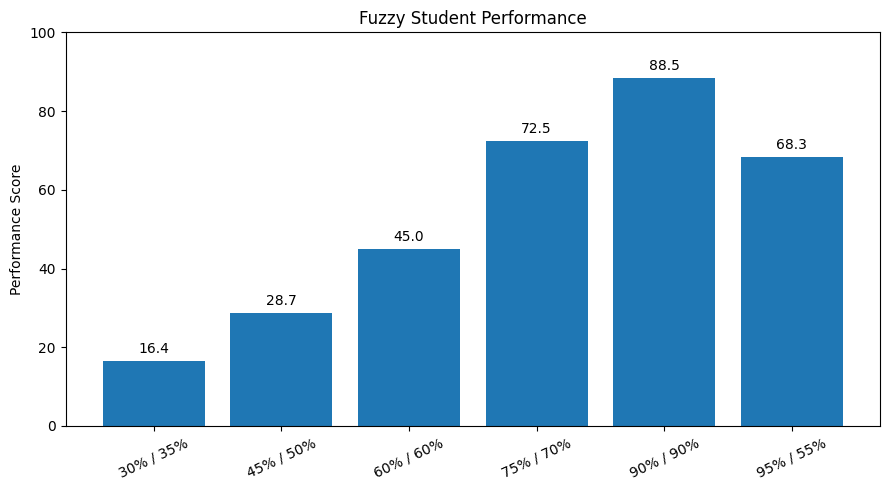

In [2]:
test_cases=[(30,35),(45,50),(60,60),(75,70),(90,90),(95,55)]
print(f"{'Attendance':>12} {'Marks':>8} {'Score':>10} {'Performance':>14}")
print('-'*50)
results=[]
for a,m in test_cases:
    score,label,*_=fuzzy_performance(a,m); results.append((a,m,score,label))
    print(f'{a:>12} {m:>8} {score:>10.2f} {label:>14}')

labels=[f'{a}% / {m}%' for a,m,_,_ in results]
scores=[s for _,_,s,_ in results]
fig,ax=plt.subplots(figsize=(9,5)); bars=ax.bar(labels,scores); ax.set_ylim(0,100); ax.set_ylabel('Performance Score'); ax.set_title('Fuzzy Student Performance')
for b,s in zip(bars,scores): ax.text(b.get_x()+b.get_width()/2,s+2,f'{s:.1f}',ha='center')
plt.xticks(rotation=25); plt.tight_layout(); plt.show()


### Observation
The fuzzy output changes smoothly with attendance and marks. Low values activate lower-performance rules, while high attendance and marks activate stronger rules such as Good and Excellent.


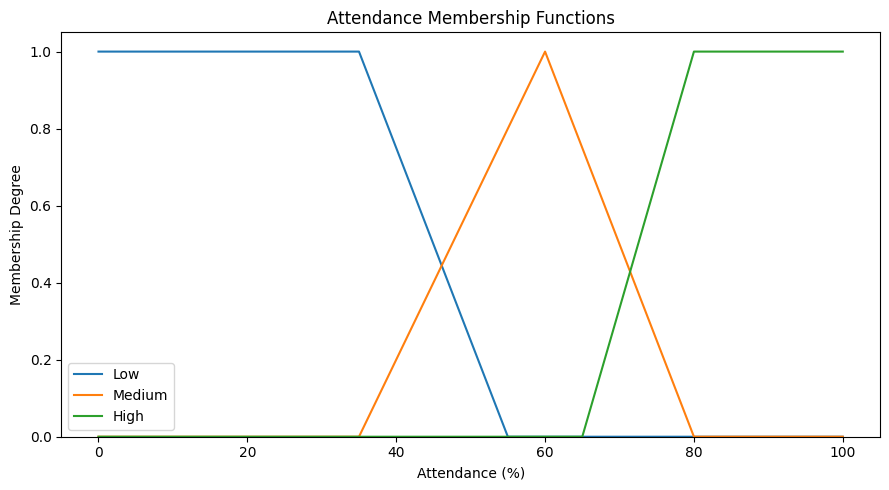

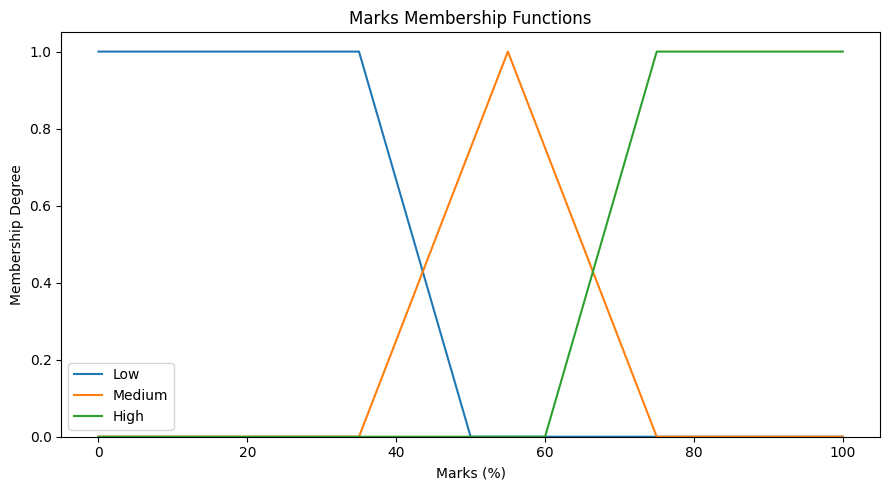

In [3]:
x=[i/2 for i in range(201)]
fig,ax=plt.subplots(figsize=(9,5))
for name in ['Low','Medium','High']: ax.plot(x,[attendance_memberships(v)[name] for v in x],label=name)
ax.set_xlabel('Attendance (%)'); ax.set_ylabel('Membership Degree'); ax.set_title('Attendance Membership Functions'); ax.set_ylim(0,1.05); ax.legend(); plt.tight_layout(); plt.show()

fig,ax=plt.subplots(figsize=(9,5))
for name in ['Low','Medium','High']: ax.plot(x,[marks_memberships(v)[name] for v in x],label=name)
ax.set_xlabel('Marks (%)'); ax.set_ylabel('Membership Degree'); ax.set_title('Marks Membership Functions'); ax.set_ylim(0,1.05); ax.legend(); plt.tight_layout(); plt.show()


# 2. Constraint Satisfaction Problem - Timetable

A CSP consists of variables, domains, and constraints.

**Variables:** AI, ML, DBMS, Mathematics.

**Time slots:** Monday 9 AM, Monday 11 AM, Tuesday 9 AM, Tuesday 11 AM.

**Constraints:**
1. No two classes can use the same slot.
2. AI must be scheduled before ML.
3. DBMS cannot be scheduled on Monday.
4. Mathematics cannot use Tuesday 11 AM.


In [4]:
subjects=['AI','ML','DBMS','Mathematics']
slots=[('Monday','9 AM'),('Monday','11 AM'),('Tuesday','9 AM'),('Tuesday','11 AM')]
def idx(s): return slots.index(s)
def valid(a):
    return (len(set(a.values()))==len(subjects) and idx(a['AI'])<idx(a['ML']) and a['DBMS'][0]!='Monday' and a['Mathematics']!=('Tuesday','11 AM'))
def solve(check=valid):
    out=[]
    for vals in itertools.permutations(slots):
        a=dict(zip(subjects,vals))
        if check(a): out.append(a)
    return out
solutions=solve()
print('Number of valid timetables:',len(solutions))
for s in subjects:
    print(f'{s:<12} -> {solutions[0][s][0]}, {solutions[0][s][1]}')


Number of valid timetables: 5
AI           -> Monday, 9 AM
ML           -> Monday, 11 AM
DBMS         -> Tuesday, 11 AM
Mathematics  -> Tuesday, 9 AM


In [5]:
print('ALL VALID TIMETABLES')
for i,a in enumerate(solutions,1):
    print(f'\nSolution {i}')
    for s in subjects: print(f'  {s:<12} -> {a[s][0]}, {a[s][1]}')


ALL VALID TIMETABLES

Solution 1
  AI           -> Monday, 9 AM
  ML           -> Monday, 11 AM
  DBMS         -> Tuesday, 11 AM
  Mathematics  -> Tuesday, 9 AM

Solution 2
  AI           -> Monday, 9 AM
  ML           -> Tuesday, 9 AM
  DBMS         -> Tuesday, 11 AM
  Mathematics  -> Monday, 11 AM

Solution 3
  AI           -> Monday, 9 AM
  ML           -> Tuesday, 11 AM
  DBMS         -> Tuesday, 9 AM
  Mathematics  -> Monday, 11 AM

Solution 4
  AI           -> Monday, 11 AM
  ML           -> Tuesday, 9 AM
  DBMS         -> Tuesday, 11 AM
  Mathematics  -> Monday, 9 AM

Solution 5
  AI           -> Monday, 11 AM
  ML           -> Tuesday, 11 AM
  DBMS         -> Tuesday, 9 AM
  Mathematics  -> Monday, 9 AM


### Observation
The solver enumerates candidate assignments and retains only those satisfying every constraint. Therefore, each reported timetable is conflict-free and respects the ordering and day restrictions.


# 3. Change in Fuzzy Rules

The rule **Medium attendance + Medium marks -> Average** is changed to **Good**.


In [6]:
modified_rules=[('Low','Low','Poor'),('Low','Medium','Poor'),('Low','High','Average'),('Medium','Low','Average'),('Medium','Medium','Good'),('Medium','High','Good'),('High','Low','Average'),('High','Medium','Good'),('High','High','Excellent')]
old=fuzzy_performance(60,60,RULES)
new=fuzzy_performance(60,60,modified_rules)
print(f'Attendance=60%, Marks=60%')
print(f'Original rule: {old[0]:.2f} -> {old[1]}')
print(f'Modified rule: {new[0]:.2f} -> {new[1]}')


Attendance=60%, Marks=60%
Original rule: 45.00 -> Average
Modified rule: 68.25 -> Good


### Observation
Changing a fuzzy rule changes the contribution of the corresponding rule to the aggregated output. Consequently, the final defuzzified score and possibly the linguistic performance category can change even though the input values remain the same.


# 4. Change in CSP Constraints

A new constraint is added: **AI cannot be scheduled on Monday.**


In [7]:
def valid_modified(a):
    return valid(a) and a['AI'][0]!='Monday'
modified_solutions=solve(valid_modified)
print('Original number of solutions:',len(solutions))
print('Modified number of solutions:',len(modified_solutions))
if modified_solutions:
    print('\nFirst modified timetable:')
    for s in subjects: print(f'{s:<12} -> {modified_solutions[0][s][0]}, {modified_solutions[0][s][1]}')


Original number of solutions: 5
Modified number of solutions: 0


### Observation
Adding a constraint reduces the feasible solution space because assignments violating the new condition are removed. This demonstrates how constraints control which combinations are acceptable in a CSP.


# 5. Fuzzy Logic vs Constraint Satisfaction

| Feature | Fuzzy Logic | CSP |
|---|---|---|
| Purpose | Handle gradual or uncertain concepts | Find assignments satisfying constraints |
| Representation | Membership degrees | Variables and domains |
| Rules | Fuzzy IF-THEN rules | Hard constraints |
| Output | Crisp score/category | Valid assignment(s) |
| Example | Student performance | Timetable |


# 6. Overall Observations

1. Fuzzy logic represents concepts such as Low, Medium, and High using membership degrees.
2. Fuzzy inference produces a smooth performance score rather than relying only on hard thresholds.
3. Changing a fuzzy rule can alter the final output.
4. A CSP models a problem using variables, domains, and constraints.
5. The timetable solver rejects assignments that violate any constraint.
6. Adding a constraint reduces the set of feasible solutions.


# 7. Conclusion

A fuzzy logic system and a constraint satisfaction problem were implemented successfully. The fuzzy system determines student performance from attendance and marks, while the CSP generates valid timetables under explicit scheduling constraints. Modifying fuzzy rules changes the inference result, whereas adding CSP constraints reduces the feasible solution space.


# 8. Viva Questions and Answers

**Q1. What is fuzzy logic?**  
A reasoning approach where variables can have membership values between 0 and 1.

**Q2. What is a membership function?**  
A function that maps an input value to its degree of membership in a fuzzy set.

**Q3. What is defuzzification?**  
Conversion of an aggregated fuzzy output into a single crisp value.

**Q4. What is centroid defuzzification?**  
It computes the center of gravity of the aggregated output membership function.

**Q5. What is a CSP?**  
A problem defined by variables, their domains, and constraints.

**Q6. What is a domain?**  
The set of possible values that can be assigned to a variable.

**Q7. What happens when a new CSP constraint is added?**  
Some previously valid assignments become invalid, reducing the feasible solution space.

**Q8. Give one application of fuzzy logic.**  
Temperature control and other control systems.

**Q9. Give one application of CSP.**  
Timetabling and scheduling.
